In [27]:
from mpl_toolkits.basemap import Basemap
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress
from matplotlib.font_manager import FontProperties
import xskillscore as xs

In [2]:
 def fractional_years(time_index):
    dt = pd.to_datetime(time_index)
    year = dt.year
    start = pd.to_datetime(year.astype(str) + "-01-01")
    end = pd.to_datetime((year+1).astype(str) + "-01-01")
    frac = (dt - start) / (end - start)
    return (year + frac.values).to_numpy()

def poly_harmonic(t, *params):
    order_poly = 3
    n_harm = 4
    poly = sum(params[i] * (t - t.mean())**i for i in range(order_poly+1))
    harmonics = sum(
        params[order_poly+1+2*(k-1)]*np.sin(2*np.pi*k*t) +
        params[order_poly+2*k]*np.cos(2*np.pi*k*t)
        for k in range(1, n_harm+1)
    )
    return poly + harmonics

def fit_model(t, y):
    order_poly, n_harm = 3, 4
    n_params = (order_poly+1) + 2*n_harm
    p0 = np.zeros(n_params)
    popt, _ = curve_fit(poly_harmonic, t, y, p0=p0, maxfev=10000)
    return popt

In [3]:
def compute_yearly_amplitudes(time, y, order_poly=3, n_harm=4):
    """
    Compute yearly seasonal amplitudes (max - min) using 
    polynomial + harmonic fit with ±1 yr window (edges use 3 years).
    Also returns the smoothed fitted series for the full timeseries.

    Parameters
    ----------
    time : pandas.DatetimeIndex
        Time array (monthly or daily).
    y : array-like
        Timeseries values (same length as time).
    order_poly : int, optional
        Polynomial order (default=3).
    n_harm : int, optional
        Number of harmonics (default=4).

    Returns
    -------
    years : np.ndarray
        Array of years.
    amplitudes : np.ndarray
        Yearly amplitudes (max - min).
    y_smooth : np.ndarray
        Smoothed fitted timeseries (same length as time).
    """
    t_years = fractional_years(time)
    y = np.asarray(y)

    years = np.arange(time.year.min(), time.year.max()+1)
    amplitudes = []
    y_smooth = np.full_like(y, np.nan, dtype=float)  # init smoothed series

    for yr in years:
        if yr == time.year.min():  
            mask = (time.year >= yr) & (time.year <= yr+2)
        elif yr == time.year.max():
            mask = (time.year >= yr-2) & (time.year <= yr)
        else:
            mask = (time.year >= yr-1) & (time.year <= yr+1)

        if mask.sum() < 6:
            amplitudes.append(np.nan)
            continue

        t_sub = t_years[mask]
        y_sub = y[mask]

        # local fit
        popt_sub = fit_model(t_sub, y_sub)
        y_model = poly_harmonic(t_sub, *popt_sub)

        # store smoothed values for this year's indices
        y_smooth[mask] = y_model  

        # compute amplitude only for this year
        df = pd.DataFrame({"t": t_sub, "y": y_model, "date": time[mask]})
        df["year"] = df["date"].dt.year
        y_this_year = df[df["year"] == yr]["y"]

        if len(y_this_year) == 0:
            amplitudes.append(np.nan)
        else:
            amplitudes.append(y_this_year.max() - y_this_year.min())

    return years, np.array(amplitudes), time, y_smooth

In [4]:


def schmidt_number(T):
    """Calculate Schmidt number for CO2 in seawater (Wanninkhof 2014)."""
    return 2116.8 - 136.25 * T + 4.7353 * T**2 - 0.092307 * T**3 + 0.0007555 * T**4

def solubility_weiss(T, S):
    """
    CO2 solubility in mol/m³/µatm from Weiss (1974).
    T: temperature in degC
    S: salinity in PSU
    """
    TK = T + 273.15  # Kelvin
    lnK0 = (-58.0931 + 90.5069 * (100 / TK) +
            22.2940 * np.log(TK / 100) +
            S * (0.027766 - 0.025888 * (TK / 100) + 0.0050578 * (TK / 100) ** 2))
    K0 = np.exp(lnK0)  # mol/L/atm
    return K0 * 1000  # convert to mol/m³/atm

def air_sea_CO2_flux(T, S, U, pCO2_sea, pCO2_air):
    """
    Calculate air-sea CO₂ flux (mol/m²/s).
    
    Parameters:
    T: Sea surface temperature (°C)
    S: Sea surface salinity (psu)
    U: Wind speed at 10 m (m/s)
    pCO2_sea: Sea surface pCO₂ (µatm)
    pCO2_air: Atmospheric pCO₂ (µatm)
    
    Returns:
    CO₂ flux in mol/m²/yr
    """
    # Schmidt number
    Sc = schmidt_number(T)

    # Gas transfer velocity k (m/s) using Wanninkhof 2014 (with unit correction)
    k_660 = 0.251 * U  # cm/hr
    k = k_660 * (Sc / 660) ** -0.5  # cm/hr
    k_m_s = k / 100 / 3600  # convert to m/s

    # Solubility α (mol/m³/µatm)
    alpha = solubility_weiss(T, S) / 1e6  # mol/m³/µatm

    # Flux (mol/m²/s)
    flux = k_m_s * alpha * (pCO2_sea - pCO2_air)  # mol/m²/s

    # Convert to mol/m²/yr
    flux_yr = flux * 60 * 60 * 24 * 365  # seconds → year

    return flux_yr


In [6]:
ds = xr.open_dataset("../pCO2-Corrected_INCOIS-BIO-ROMS.nc")
pco2 = ds["pCO2_Clim"]  # shape: (TIME, LAT, LON)
pco2_dev = pco2 + ds["Deviant_uncertainty"]
temp = ds["SST"]
sal = ds["SSS"]

In [8]:
pco2_atm = xr.open_dataset('../pCO2_atm_gridded_1deg.nc').pCO2_atm
pco2_atm = pco2_atm.rename({"time":"TIME","lat":"LAT","lon":"LON"})
pco2_atm['TIME'] = ds.TIME
pco2_atm = pco2_atm.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [9]:
sp = xr.open_dataset('JRA_WS_second_moment_following_Fay_et_al.nc').ws
sp = sp.rename({'time':'TIME','lat':'LAT','lon':'LON'})
sp['TIME'] = ds.TIME
sp = sp.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [10]:
sp_std = xr.open_dataset('JRA_WS_second_moment_following_Fay_et_al.nc').ws_std
sp_std = sp_std.rename({'time':'TIME','lat':'LAT','lon':'LON'})
sp_std['TIME'] = ds.TIME
sp_std = sp_std.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [11]:
ws = sp**2 + sp_std**2

In [12]:
# ws = xr.open_dataset('wind_speed_JRA.nc').WS
# ws['TIME'] = ds.TIME
# ws = ws.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [13]:
mask_pco2 = pco2.mean(dim=['TIME']).notnull()

In [14]:
ws = ws.where(mask_pco2)
pco2_atm = pco2_atm.where(mask_pco2)

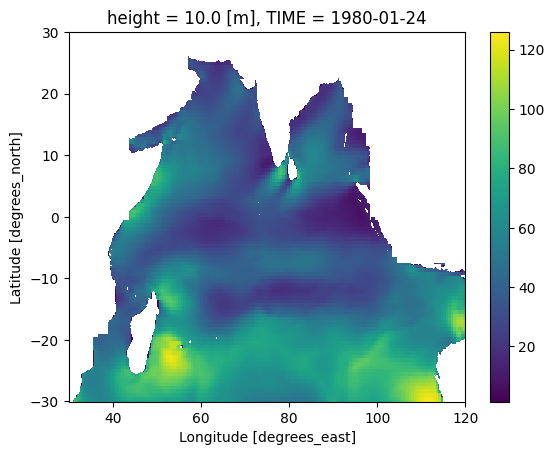

In [15]:
ws[0].plot()

In [16]:


# Average over lat & lon -> 1D timeseries
time = pd.to_datetime(pco2["TIME"].values)
# Arabian Sea
pco2_AS = pco2.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_dev_AS = pco2_dev.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_AS = temp.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_AS = sal.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_AS = pco2_atm.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_AS = ws.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])

# Bay of Bengal
pco2_BoB = pco2.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_dev_BoB = pco2_dev.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_BoB = temp.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_BoB = sal.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_BoB = pco2_atm.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_BoB = ws.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])

# Equatorial Indian Ocean
pco2_EIO = pco2.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
pco2_dev_EIO = pco2_dev.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
temp_EIO = temp.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
sal_EIO = sal.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
pco2_atm_EIO = pco2_atm.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
ws_EIO = ws.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])


# Southern Indian Ocean
pco2_SIO = pco2.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
pco2_dev_SIO = pco2_dev.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
temp_SIO = temp.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
sal_SIO = sal.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
pco2_atm_SIO = pco2_atm.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
ws_SIO = ws.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])




In [17]:
flux_IO = air_sea_CO2_flux(temp, sal, ws, pco2, pco2_atm)

In [18]:
flux_IO

<xarray.DataArray (TIME: 480, LAT: 756, LON: 1081)> Size: 3GB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
    height   float64 8B 10.0
  * TIME     (TIME) datetime64[ns] 4kB 1980-01-24 1980-02-23 ... 2019-12-25
  * LAT      (LAT) float32 3kB -30.0 -29.92 -29.85 -29.78 ... 29.83 29.91 29.98
  * LON      (LON) float32 4kB 30.0 30.08 30.17 30.25 ... 119.8 119.9 120.0

In [19]:
flux_IO_amp = flux_IO.groupby('TIME.year').max() - flux_IO.groupby('TIME.year').min()
flux_IO_amp

<xarray.DataArray (year: 40, LAT: 756, LON: 1081)> Size: 262MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
    height   float64 8B 10.0
  * LAT      (LAT) float32 3kB -30.0 -29.92 -29.85 -29.78 ... 29.83 29.91 29.98
  * LON      (LON) float32 4kB 30.0 30.08 30.17 30.25 ... 119.8 119.9 120.0
  * year     (year) int64 320B 1980 1981 1982 1983 1984 ... 2016 2017 2018 2019

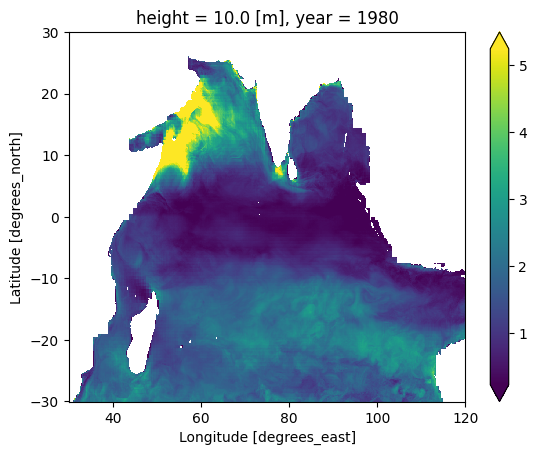

In [20]:
flux_IO_amp[0].plot(robust=True)

In [21]:
from scipy.stats import linregress
def reg_line(a):
    slope, intercept, rvalue, pvalue, stderr = linregress(np.arange(1,len(a)+1),a)
    reg=slope*np.arange(1,len(a)+1)+intercept
    return reg,slope,pvalue,stderr

def calculate_slope(data_array):
    slopes = np.apply_along_axis(lambda y: linregress(range(len(y)), y).slope, axis=0, arr=data_array)
    return slopes


def calculate_pval(data_array):
    pvals = np.apply_along_axis(lambda y: linregress(range(len(y)), y).pvalue, axis=0, arr=data_array)
    return pvals

def calculate_intercept(data_array):
    pvals = np.apply_along_axis(lambda y: linregress(range(len(y)), y).intercept, axis=0, arr=data_array)
    return pvals

def spatial_trend(data):
    slope = xr.apply_ufunc(
        calculate_slope,
        data,
        input_core_dims=[["year"]],  # Apply along 'time' dimension
        vectorize=True
    )
    return slope*10

In [22]:
flux_amp_trend = spatial_trend(flux_IO_amp)

In [23]:
flux_amp_trend

<xarray.DataArray (LAT: 756, LON: 1081)> Size: 7MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
    height   float64 8B 10.0
  * LAT      (LAT) float32 3kB -30.0 -29.92 -29.85 -29.78 ... 29.83 29.91 29.98
  * LON      (LON) float32 4kB 30.0 30.08 30.17 30.25 ... 119.8 119.9 120.0

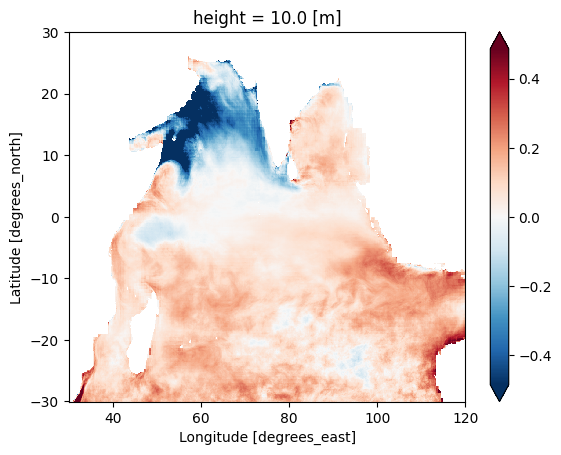

In [24]:
flux_amp_trend.plot(robust=True)

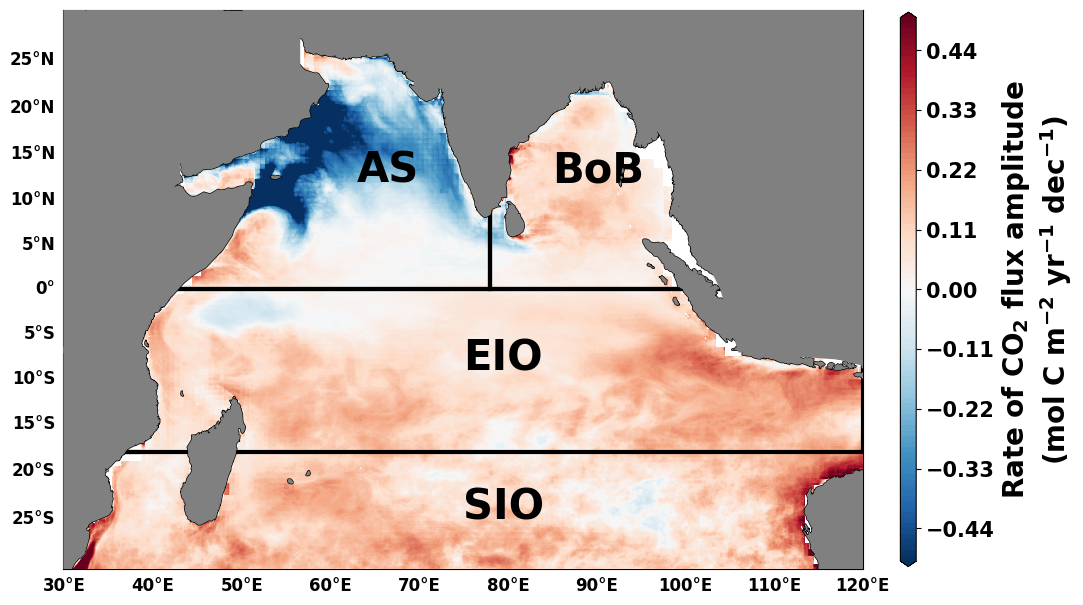

In [31]:
plt.rcParams['font.weight']='bold'
fig,ax=plt.subplots(1,1,figsize=(12,10),sharey=True)
plt.subplots_adjust(wspace=0.1,hspace=-0.1)

map = Basemap(projection='merc', resolution='l',
                llcrnrlat=-30, urcrnrlat = 30,
                llcrnrlon=30, urcrnrlon = 120)
kk=30


lon1=[30,78,78,30,30]
lat1=[0,0,30,30,0]
x1,y1=map(lon1,lat1)
map.plot(x1,y1,color='k',linewidth=3,zorder=6)

xx1,yy1=map(63,12)
plt.text(xx1,yy1,"AS",color="k",fontsize=kk,zorder=6)

lon2=[78,120,120,78,78]
lat2=[0,0,30,30,0]
x2,y2=map(lon2,lat2)
map.plot(x2,y2,color='k',linewidth=3,zorder=6)

xx2,yy2=map(85,12)
plt.text(xx2,yy2,"BoB",color="k",fontsize=kk,zorder=6)

lon3=[30,120,120,30,30]
lat3=[-18,-18,0,0,-18]
x3,y3=map(lon3,lat3)
map.plot(x3,y3,color='k',linewidth=3,zorder=6)

xx3,yy3=map(75,-9)
plt.text(xx3,yy3,"EIO",color="k",fontsize=kk,zorder=6)

lon4=[30,120,120,30,30]
lat4=[-30,-30,-18,-18,-30]
x4,y4=map(lon4,lat4)
map.plot(x4,y4,color='k',linewidth=3)

xx4,yy4=map(75,-25)
plt.text(xx4,yy4,"SIO",color="k",fontsize=kk,zorder=6)






# map.fillcontinents(color='gray',lake_color='aqua')
# map.drawcoastlines()
# map.drawmapboundary(fill_color='gray')
# map.drawparallels(range(-90, 100, 5), linewidth=1, dashes=[4, 2], labels=[1,0,0,1], color='k', zorder=10,fontsize=20,fontweight='bold')
# map.drawmeridians(range(50, 120, 10),labels=[1,0,0,1],color='k', zorder=10,fontsize=20,fontweight='bold', linewidth=1)
lon,lat=np.meshgrid(flux_amp_trend.LON,flux_amp_trend.LAT)
x,y=map(lon,lat)
pp=ax.contourf(x,y,flux_amp_trend,55,cmap='RdBu_r',levels=np.arange(-0.5,0.51,0.01),extend='both',zorder=5)

# for i in range(1):
map.fillcontinents(color='gray',lake_color='gray',ax=ax,zorder=20)
map.drawcoastlines(ax=ax,zorder=18)
 
# map.drawparallels(range(-90, 100, 5), linewidth=1,ax=ax, dashes=[4, 2], color='k', zorder=10,fontsize=20,fontweight='bold')
# map.drawmeridians(range(50, 120, 10),color='k',ax=ax, zorder=10,fontsize=20,fontweight='bold', linewidth=1)

    
    # map.drawmapboundary(fill_color='gray')
    # if i in [0]:
map.drawparallels(range(-90, 100, 5), linewidth=1,ax=ax, labels=[1,0,0,0], color='w', zorder=2,fontsize=12,fontweight='bold')
    # if i in [0,1]:
map.drawmeridians(range(30, 122, 10),labels=[0,0,0,1],color='w',ax=ax, zorder=2,fontsize=12,fontweight='bold', linewidth=1)
# map.drawparallels(range(-90, 100, 10), linewidth=0, labels=[1,0,0,1],color='white', zorder=0,fontsize=16,fontweight='bold')
# map.drawmeridians(range(40, 120, 10),linewidth=0,labels=[1,0,0,1],color='white', zorder=0,fontsize=16,fontweight='bold')

china_coords = [(106,-5),(120,-8.5),(120,29.5),(100,29.5),(99,10),(104,0),(106,-7),(120,-8)]
china_x,china_y = zip(*[map(lon,lat) for lon,lat in china_coords])

ax.fill(china_x,china_y,color='grey',zorder=19)

victo_coords = [(31,-20),(35,-20),(35,1),(31,1),(31,-20)]
victo_x,victo_y = zip(*[map(lon,lat) for lon,lat in victo_coords])
ax.fill(victo_x,victo_y,color='grey',zorder=3)

indi_coords = [(69.5,22),(92,23),(92,28),(69.5,28),(69.5,22)]
indi_x,indi_y = zip(*[map(lon,lat) for lon,lat in indi_coords])
ax.fill(indi_x,indi_y,color='grey',zorder=19)

indi_coords = [(65,26),(70,26),(70,29),(65,29),(65,26)]
indi_x,indi_y = zip(*[map(lon,lat) for lon,lat in indi_coords])
ax.fill(indi_x,indi_y,color='grey',zorder=19)


uae = [(30.5, 12), (43, 12), (43, 29.9), (30.5, 29.9), (30.5, 12)]
uae_x,uae_y = zip(*[map(lon,lat) for lon,lat in uae])
ax.fill(uae_x,uae_y,color='grey',zorder=19)

uae1 = [(30.5, 23), (56.5, 23), (56.5, 29.9), (30.5, 29.9), (30.5, 23)]
uae1_x,uae1_y = zip(*[map(lon,lat) for lon,lat in uae1])
ax.fill(uae1_x,uae1_y,color='grey',zorder=19)


cb=fig.colorbar(pp,ax=ax,pad=0.04,orientation='vertical',shrink=0.72,fraction=0.1,aspect=35,extendfrac='auto',extend='both')
cb.set_label(r'Rate of $\mathbf{CO_{2}}$ flux amplitude'
             '\n'
             r'(mol C m$\mathbf{^{-2}}$ yr$\mathbf{^{-1}}$ dec$\mathbf{^{-1}}$)',
             fontweight='bold', fontsize=20)
# cb1=fig.colorbar(qq,ax=ax[0],pad=0.04,orientation='horizontal',shrink=0.95,fraction=0.1,aspect=55,extendfrac='auto',extend='both')
# for i, ax in enumerate(ax):
#         label = f"({chr(ord('a') + i)})"
#         ax.text(0.01, 0.9, label, transform=ax.transAxes, fontsize=15, fontweight="bold", va="top")

cb.ax.tick_params(labelsize=15)
# plt.savefig('study_region.png', transparent=None, dpi=400, bbox_inches='tight', facecolor='white', edgecolor='white')

# Area

In [32]:
mask_AS = pco2.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['TIME']).notnull()
mask_BoB = pco2.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['TIME']).notnull()
mask_EIO = pco2.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['TIME']).notnull()
mask_SIO = pco2.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['TIME']).notnull()

In [33]:
area_AS = mask_AS.sum()*64*(10**6)
area_BoB = mask_BoB.sum()*64*(10**6)
area_EIO = mask_EIO.sum()*64*(10**6)
area_SIO = mask_SIO.sum()*64*(10**6)

# AS

In [34]:
years, amplitudes1AS, time, pco2_sm_AS = compute_yearly_amplitudes(time, pco2_AS.values)
years, amplitudes1AS, time, pco2_dev_sm_AS = compute_yearly_amplitudes(time, pco2_dev_AS.values)
years, amplitudes2AS, time, temp_sm_AS = compute_yearly_amplitudes(time, temp_AS.values)
years, amplitudes3AS, time, sal_sm_AS = compute_yearly_amplitudes(time, sal_AS.values)
years, amplitudes2AS, time, pco2_atm_sm_AS = compute_yearly_amplitudes(time, pco2_atm_AS.values)
years, amplitudes3AS, time, ws_sm_AS = compute_yearly_amplitudes(time, ws_AS.values)

In [35]:
pco2_sm_AS = xr.DataArray(
    pco2_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_sm_AS"
)

pco2_dev_sm_AS = xr.DataArray(
    pco2_dev_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_dev_sm_AS"
)

temp_sm_AS = xr.DataArray(
    temp_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_sm_AS"
)

sal_sm_AS = xr.DataArray(
    sal_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="sal_sm_AS"
)

pco2_atm_sm_AS = xr.DataArray(
    pco2_atm_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_atm_sm_AS"
)

ws_sm_AS = xr.DataArray(
    ws_sm_AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="ws_sm_AS"
)

In [36]:
flux_sm_AS = air_sea_CO2_flux(temp_sm_AS, sal_sm_AS, ws_sm_AS, pco2_sm_AS, pco2_atm_sm_AS)*area_AS*(12.0 / 1e15)

In [37]:
flux_sm_AS_un = air_sea_CO2_flux(temp_sm_AS, sal_sm_AS, ws_sm_AS, pco2_dev_sm_AS, pco2_atm_sm_AS)*area_AS*(12.0 / 1e15)

# BoB

In [38]:
years, amplitudes1BoB, time, pco2_sm_BoB = compute_yearly_amplitudes(time, pco2_BoB.values)
years, amplitudes1BoB, time, pco2_dev_sm_BoB = compute_yearly_amplitudes(time, pco2_dev_BoB.values)
years, amplitudes2BoB, time, temp_sm_BoB = compute_yearly_amplitudes(time, temp_BoB.values)
years, amplitudes3BoB, time, sal_sm_BoB = compute_yearly_amplitudes(time, sal_BoB.values)
years, amplitudes2BoB, time, pco2_atm_sm_BoB = compute_yearly_amplitudes(time, pco2_atm_BoB.values)
years, amplitudes3BoB, time, ws_sm_BoB = compute_yearly_amplitudes(time, ws_BoB.values)

In [39]:
pco2_sm_BoB = xr.DataArray(
    pco2_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_sm_BoB"
)

pco2_dev_sm_BoB = xr.DataArray(
    pco2_dev_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_dev_sm_BoB"
)

temp_sm_BoB = xr.DataArray(
    temp_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_sm_BoB"
)

sal_sm_BoB = xr.DataArray(
    sal_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="sal_sm_BoB"
)

pco2_atm_sm_BoB = xr.DataArray(
    pco2_atm_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_atm_sm_BoB"
)

ws_sm_BoB = xr.DataArray(
    ws_sm_BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="ws_sm_BoB"
)

In [40]:
flux_sm_BoB = air_sea_CO2_flux(temp_sm_BoB, sal_sm_BoB, ws_sm_BoB, pco2_sm_BoB, pco2_atm_sm_BoB)*area_BoB*(12.0 / 1e15)

In [41]:
flux_no_sm_BoB = air_sea_CO2_flux(temp_BoB, sal_BoB, ws_BoB, pco2_BoB, pco2_atm_BoB)*area_BoB*(12.0 / 1e15)

In [42]:
# years, amplitudes1BoB, time, flux_s_BoB = compute_yearly_amplitudes(time, flux_no_sm_BoB.values)

In [43]:
# flux_s_BoB = xr.DataArray(
#     flux_s_BoB,
#     coords={"TIME": time},
#     dims=["TIME"],
#     name="flux_s_BoB"
# )

In [44]:
flux_sm_BoB_yr = flux_sm_BoB.groupby('TIME.year').mean()
flux_no_sm_BoB_yr = flux_no_sm_BoB.groupby('TIME.year').mean()
# flux_s_BoB_yr = flux_s_BoB.groupby('TIME.year').mean()

In [45]:
perc = (flux_sm_BoB_yr-flux_no_sm_BoB_yr)*100/flux_no_sm_BoB_yr

In [46]:
# plt.rcParams["font.weight"]='bold'
# fig,ax = plt.subplots(1,1,figsize=(10, 3))

# ay = ax.twinx()
# flux_sm_BoB_yr.plot(linestyle='--',ax=ax,label='Smooth',linewidth=2,c='r')
# flux_no_sm_BoB_yr.plot(linestyle='-',ax=ax,label='No_smoothing',linewidth=2,c='b')


# # ax.set_ylim([-0.04,0.04])

# perc.plot(linestyle=':',c='g',ax=ay,label="percentage_change")

# # ay.set_ylim([-0.05,0.05])
# ax.legend(loc='best', bbox_to_anchor=(0.15, 0.01, 0.5, 0.5),ncols=3)
# ay.legend()
# ax.set_xlabel('Years',fontsize=18, fontweight="bold")
# ax.set_ylabel(r"CO$\mathbf{_2}$ flux",fontsize=14, fontweight="bold")
# ay.set_ylabel(r"chnage (%)",fontsize=14, fontweight="bold")
# # plt.savefig('flux_diff_with_without_smooth.png', dpi=500, bbox_inches='tight', facecolor='white')

In [47]:
flux_sm_BoB_un = air_sea_CO2_flux(temp_sm_BoB, sal_sm_BoB, ws_sm_BoB, pco2_dev_sm_BoB, pco2_atm_sm_BoB)*area_BoB*(12.0 / 1e15)

# EIO

In [48]:
years, amplitudes1EIO, time, pco2_sm_EIO = compute_yearly_amplitudes(time, pco2_EIO.values)
years, amplitudes1EIO, time, pco2_dev_sm_EIO = compute_yearly_amplitudes(time, pco2_dev_EIO.values)
years, amplitudes2EIO, time, temp_sm_EIO = compute_yearly_amplitudes(time, temp_EIO.values)
years, amplitudes3EIO, time, sal_sm_EIO = compute_yearly_amplitudes(time, sal_EIO.values)
years, amplitudes2EIO, time, pco2_atm_sm_EIO = compute_yearly_amplitudes(time, pco2_atm_EIO.values)
years, amplitudes3EIO, time, ws_sm_EIO = compute_yearly_amplitudes(time, ws_EIO.values)

In [49]:
pco2_sm_EIO = xr.DataArray(
    pco2_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_sm_EIO"
)

pco2_dev_sm_EIO = xr.DataArray(
    pco2_dev_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_dev_sm_EIO"
)

temp_sm_EIO = xr.DataArray(
    temp_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_sm_EIO"
)

sal_sm_EIO = xr.DataArray(
    sal_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="sal_sm_EIO"
)

pco2_atm_sm_EIO = xr.DataArray(
    pco2_atm_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_atm_sm_EIO"
)

ws_sm_EIO = xr.DataArray(
    ws_sm_EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="ws_sm_EIO"
)

In [50]:
flux_sm_EIO = air_sea_CO2_flux(temp_sm_EIO, sal_sm_EIO, ws_sm_EIO, pco2_sm_EIO, pco2_atm_sm_EIO)*area_EIO*(12.0 / 1e15)

In [51]:
flux_sm_EIO_un = air_sea_CO2_flux(temp_sm_EIO, sal_sm_EIO, ws_sm_EIO, pco2_dev_sm_EIO, pco2_atm_sm_EIO)*area_EIO*(12.0 / 1e15)

# SIO

In [52]:
years, amplitudes1SIO, time, pco2_sm_SIO = compute_yearly_amplitudes(time, pco2_SIO.values)
years, amplitudes1SIO, time, pco2_dev_sm_SIO = compute_yearly_amplitudes(time, pco2_dev_SIO.values)
years, amplitudes2SIO, time, temp_sm_SIO = compute_yearly_amplitudes(time, temp_SIO.values)
years, amplitudes3SIO, time, sal_sm_SIO = compute_yearly_amplitudes(time, sal_SIO.values)
years, amplitudes2SIO, time, pco2_atm_sm_SIO = compute_yearly_amplitudes(time, pco2_atm_SIO.values)
years, amplitudes3SIO, time, ws_sm_SIO = compute_yearly_amplitudes(time, ws_SIO.values)

In [53]:
pco2_sm_SIO = xr.DataArray(
    pco2_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_sm_SIO"
)

pco2_dev_sm_SIO = xr.DataArray(
    pco2_dev_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_dev_sm_SIO"
)

temp_sm_SIO = xr.DataArray(
    temp_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_sm_SIO"
)

sal_sm_SIO = xr.DataArray(
    sal_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="sal_sm_SIO"
)

pco2_atm_sm_SIO = xr.DataArray(
    pco2_atm_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_atm_sm_SIO"
)

ws_sm_SIO = xr.DataArray(
    ws_sm_SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="ws_sm_SIO"
)

In [54]:
flux_sm_SIO = air_sea_CO2_flux(temp_sm_SIO, sal_sm_SIO, ws_sm_SIO, pco2_sm_SIO, pco2_atm_sm_SIO)*area_SIO*(12.0 / 1e15)

In [55]:
flux_sm_SIO_un = air_sea_CO2_flux(temp_sm_SIO, sal_sm_SIO, ws_sm_SIO, pco2_dev_sm_SIO, pco2_atm_sm_SIO)*area_SIO*(12.0 / 1e15)

# Interannual long-term trend in amp

In [56]:
flux_AS_amp = flux_sm_AS.groupby('TIME.year').max() - flux_sm_AS.groupby('TIME.year').min()
flux_BoB_amp = flux_sm_BoB.groupby('TIME.year').max() - flux_sm_BoB.groupby('TIME.year').min()
flux_EIO_amp = flux_sm_EIO.groupby('TIME.year').max() - flux_sm_EIO.groupby('TIME.year').min()
flux_SIO_amp = flux_sm_SIO.groupby('TIME.year').max() - flux_sm_SIO.groupby('TIME.year').min()

flux_AS_amp_un = flux_sm_AS_un.groupby('TIME.year').max() - flux_sm_AS_un.groupby('TIME.year').min()
flux_BoB_amp_un = flux_sm_BoB_un.groupby('TIME.year').max() - flux_sm_BoB_un.groupby('TIME.year').min()
flux_EIO_amp_un = flux_sm_EIO_un.groupby('TIME.year').max() - flux_sm_EIO_un.groupby('TIME.year').min()
flux_SIO_amp_un = flux_sm_SIO_un.groupby('TIME.year').max() - flux_sm_SIO_un.groupby('TIME.year').min()

er_amp_AS = flux_AS_amp_un - flux_AS_amp
er_amp_BoB = flux_BoB_amp_un - flux_BoB_amp
er_amp_EIO = flux_EIO_amp_un - flux_EIO_amp
er_amp_SIO = flux_SIO_amp_un - flux_SIO_amp

In [57]:
flux_AS_mean = flux_sm_AS.groupby('TIME.year').mean()
flux_BoB_mean = flux_sm_BoB.groupby('TIME.year').mean()
flux_EIO_mean = flux_sm_EIO.groupby('TIME.year').mean()
flux_SIO_mean = flux_sm_SIO.groupby('TIME.year').mean()

flux_AS_mean_un = flux_sm_AS_un.groupby('TIME.year').mean()
flux_BoB_mean_un = flux_sm_BoB_un.groupby('TIME.year').mean()
flux_EIO_mean_un = flux_sm_EIO_un.groupby('TIME.year').mean()
flux_SIO_mean_un = flux_sm_SIO_un.groupby('TIME.year').mean()

er_un_AS = flux_AS_mean_un - flux_AS_mean
er_un_BoB = flux_BoB_mean_un - flux_BoB_mean
er_un_EIO = flux_EIO_mean_un - flux_EIO_mean
er_un_SIO = flux_SIO_mean_un - flux_SIO_mean

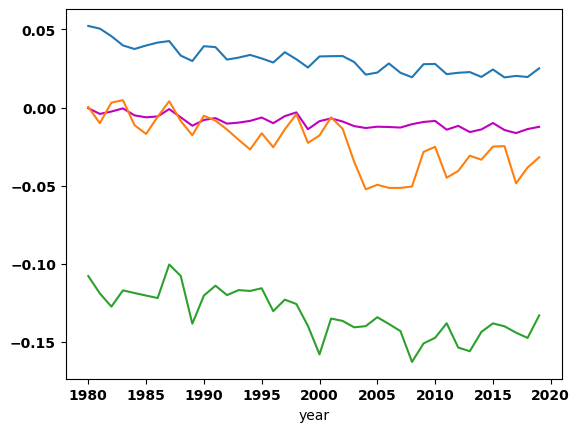

In [58]:
flux_AS_mean.plot()
flux_BoB_mean.plot(c='m')
flux_EIO_mean.plot()
flux_SIO_mean.plot()

In [59]:
slope_meanAS, intercept_meanAS, r_meanvalue_meanAS, p_meanvalue_meanAS, std_meanerr_meanAS = linregress(years, flux_AS_mean.values)
slope_meanBoB, intercept_meanBoB, r_meanvalue_meanBoB, p_meanvalue_meanBoB, std_meanerr_meanBoB = linregress(years, flux_BoB_mean.values)
slope_meanEIO, intercept_meanEIO, r_meanvalue_meanEIO, p_meanvalue_meanEIO, std_meanerr_meanEIO = linregress(years, flux_EIO_mean.values)
slope_meanSIO, intercept_meanSIO, r_meanvalue_meanSIO, p_meanvalue_meanSIO, std_meanerr_meanSIO = linregress(years, flux_SIO_mean.values)

print(f"Trend_mean_AS: {slope_meanAS*10:.3f} ± {std_meanerr_meanAS*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_meanvalue_meanAS:.3f})")
print(f"Trend_mean_BoB: {slope_meanBoB*10:.3f} ± {std_meanerr_meanBoB*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_meanvalue_meanBoB:.3f})")
print(f"Trend_mean_EIO: {slope_meanEIO*10:.3f} ± {std_meanerr_meanEIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_meanvalue_meanEIO:.3f})")
print(f"Trend_mean_SIO: {slope_meanSIO*10:.3f} ± {std_meanerr_meanSIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_meanvalue_meanSIO:.3f})")

Trend_mean_AS: -0.007 ± 0.001 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.000)
Trend_mean_BoB: -0.003 ± 0.000 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.000)
Trend_mean_EIO: -0.011 ± 0.002 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.000)
Trend_mean_SIO: -0.010 ± 0.001 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.000)


In [60]:
flux_AS_mean80 = flux_AS_mean.sel(year=slice(1980,1989)).mean()
flux_BoB_mean80 = flux_BoB_mean.sel(year=slice(1980,1989)).mean()
flux_EIO_mean80 = flux_EIO_mean.sel(year=slice(1980,1989)).mean()
flux_SIO_mean80 = flux_SIO_mean.sel(year=slice(1980,1989)).mean()

In [61]:
flux_AS_mean19 = flux_AS_mean.sel(year=slice(2010,2019)).mean()
flux_BoB_mean19 = flux_BoB_mean.sel(year=slice(2010,2019)).mean()
flux_EIO_mean19 = flux_EIO_mean.sel(year=slice(2010,2019)).mean()
flux_SIO_mean19 = flux_SIO_mean.sel(year=slice(2010,2019)).mean()

In [62]:
flux_BoB_mean19,flux_BoB_mean80

(<xarray.DataArray ()> Size: 8B
 array(-0.01312156),
 <xarray.DataArray ()> Size: 8B
 array(-0.0043744))

In [63]:
np.abs((flux_SIO_mean19.values-flux_SIO_mean80.values))

0.026261658697108378

In [64]:
per_80_19_AS = (flux_AS_mean19.values-flux_AS_mean80.values)*100/flux_AS_mean80.values
per_80_19_BoB = (flux_BoB_mean19.values-flux_BoB_mean80.values)*100/flux_BoB_mean80.values
per_80_19_EIO = (flux_EIO_mean19.values-flux_EIO_mean80.values)*100/flux_EIO_mean80.values
per_80_19_SIO = (flux_SIO_mean19.values-flux_SIO_mean80.values)*100/flux_SIO_mean80.values
print(per_80_19_AS,per_80_19_BoB,per_80_19_EIO,per_80_19_SIO)

-46.1211863562679 199.96277023763145 488.2797559724484 22.26261404158386


In [65]:
flux_AS_mean1 = flux_AS_mean.sel(year=slice(1980,1989))
flux_BoB_mean1 = flux_BoB_mean.sel(year=slice(1980,1989))
flux_EIO_mean1 = flux_EIO_mean.sel(year=slice(1980,1989))
flux_SIO_mean1 = flux_SIO_mean.sel(year=slice(1980,1989))

In [66]:
flux_AS_mean2 = flux_AS_mean.sel(year=slice(2010,2019))
flux_BoB_mean2 = flux_BoB_mean.sel(year=slice(2010,2019))
flux_EIO_mean2 = flux_EIO_mean.sel(year=slice(2010,2019))
flux_SIO_mean2 = flux_SIO_mean.sel(year=slice(2010,2019))

In [67]:
years1 = years[0:10]

In [68]:
years2 = years[30:40]
years2

array([2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019])

In [69]:
slope_mean1AS, intercept_mean1AS, r_mean1value_mean1AS, p_mean1value_mean1AS, std_mean1err_mean1AS = linregress(years1, flux_AS_mean1.values)
slope_mean1BoB, intercept_mean1BoB, r_mean1value_mean1BoB, p_mean1value_mean1BoB, std_mean1err_mean1BoB = linregress(years1, flux_BoB_mean1.values)
slope_mean1EIO, intercept_mean1EIO, r_mean1value_mean1EIO, p_mean1value_mean1EIO, std_mean1err_mean1EIO = linregress(years1, flux_EIO_mean1.values)
slope_mean1SIO, intercept_mean1SIO, r_mean1value_mean1SIO, p_mean1value_mean1SIO, std_mean1err_mean1SIO = linregress(years1, flux_SIO_mean1.values)

print(f"Trend_mean1_AS: {slope_mean1AS*10:.3f} ± {std_mean1err_mean1AS*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean1value_mean1AS:.3f})")
print(f"Trend_mean1_BoB: {slope_mean1BoB*10:.3f} ± {std_mean1err_mean1BoB*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean1value_mean1BoB:.3f})")
print(f"Trend_mean1_EIO: {slope_mean1EIO*10:.3f} ± {std_mean1err_mean1EIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean1value_mean1EIO:.3f})")
print(f"Trend_mean1_SIO: {slope_mean1SIO*10:.3f} ± {std_mean1err_mean1SIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean1value_mean1SIO:.3f})")

Trend_mean1_AS: -0.020 ± 0.004 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.001)
Trend_mean1_BoB: -0.008 ± 0.003 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.036)
Trend_mean1_EIO: -0.011 ± 0.009 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.248)
Trend_mean1_SIO: -0.005 ± 0.012 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.714)


In [70]:
slope_mean2AS, intercept_mean2AS, r_mean2value_mean2AS, p_mean2value_mean2AS, std_mean2err_mean2AS = linregress(years2, flux_AS_mean2.values)
slope_mean2BoB, intercept_mean2BoB, r_mean2value_mean2BoB, p_mean2value_mean2BoB, std_mean2err_mean2BoB = linregress(years2, flux_BoB_mean2.values)
slope_mean2EIO, intercept_mean2EIO, r_mean2value_mean2EIO, p_mean2value_mean2EIO, std_mean2err_mean2EIO = linregress(years2, flux_EIO_mean2.values)
slope_mean2SIO, intercept_mean2SIO, r_mean2value_mean2SIO, p_mean2value_mean2SIO, std_mean2err_mean2SIO = linregress(years2, flux_SIO_mean2.values)

print(f"Trend_mean2_AS: {slope_mean2AS*10:.3f} ± {std_mean2err_mean2AS*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean2value_mean2AS:.3f})")
print(f"Trend_mean2_BoB: {slope_mean2BoB*10:.3f} ± {std_mean2err_mean2BoB*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean2value_mean2BoB:.3f})")
print(f"Trend_mean2_EIO: {slope_mean2EIO*10:.3f} ± {std_mean2err_mean2EIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean2value_mean2EIO:.3f})")
print(f"Trend_mean2_SIO: {slope_mean2SIO*10:.3f} ± {std_mean2err_mean2SIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_mean2value_mean2SIO:.3f})")

Trend_mean2_AS: -0.003 ± 0.003 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.331)
Trend_mean2_BoB: -0.003 ± 0.003 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.330)
Trend_mean2_EIO: -0.002 ± 0.010 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.872)
Trend_mean2_SIO: 0.010 ± 0.008 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.228)


In [71]:
slope_AS, intercept_AS, r_value_AS, p_value_AS, std_err_AS = linregress(years, flux_AS_amp.values)
slope_BoB, intercept_BoB, r_value_BoB, p_value_BoB, std_err_BoB = linregress(years, flux_BoB_amp.values)
slope_EIO, intercept_EIO, r_value_EIO, p_value_EIO, std_err_EIO = linregress(years, flux_EIO_amp.values)
slope_SIO, intercept_SIO, r_value_SIO, p_value_SIO, std_err_SIO = linregress(years, flux_SIO_amp.values)

print(f"Trend_amp_AS: {slope_AS*10:.3f}± {std_err_AS*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_value_AS:.2f})")
print(f"Trend_amp_BoB: {slope_BoB*10:.3f}± {std_err_BoB*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_value_BoB:.2f})")
print(f"Trend_amp_EIO: {slope_EIO*10:.3f}± {std_err_EIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p<0.1({p_value_EIO:.2f})")
print(f"Trend_amp_SIO: {slope_SIO*10:.3f}± {std_err_SIO*10:.3f} PgC yr⁻¹ dec⁻¹, p = p>0.1({p_value_SIO:.2f})")

Trend_amp_AS: -0.012± 0.002 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.00)
Trend_amp_BoB: 0.000± 0.000 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.70)
Trend_amp_EIO: 0.014± 0.002 PgC yr⁻¹ dec⁻¹, p = p<0.1(0.00)
Trend_amp_SIO: 0.011± 0.003 PgC yr⁻¹ dec⁻¹, p = p>0.1(0.00)


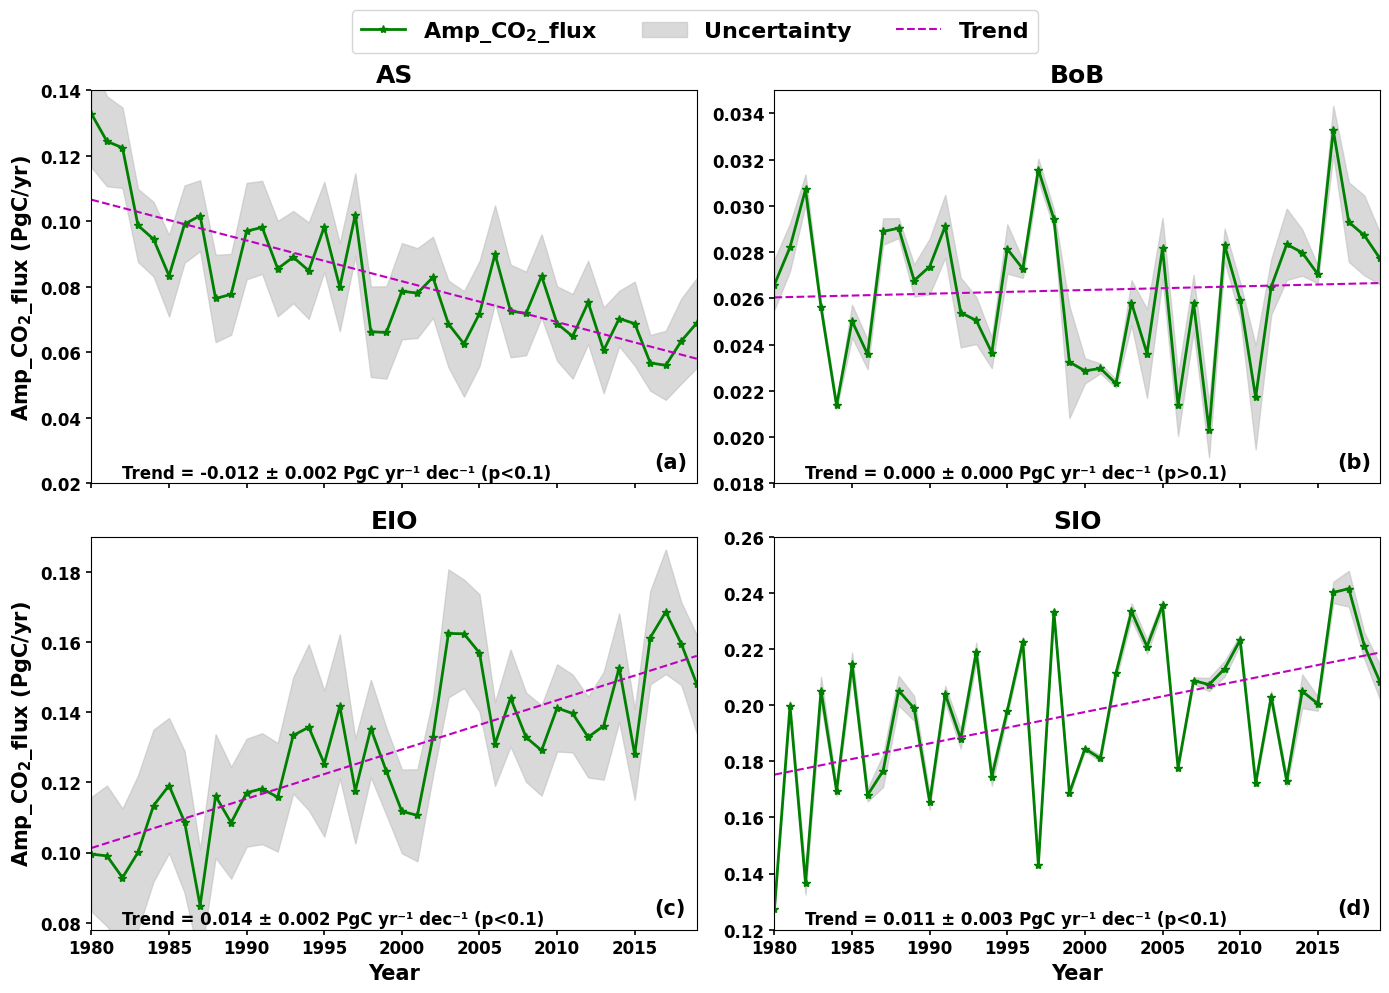

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# Region information for looping
regions = [
    ("AS", flux_AS_amp.values, er_amp_AS.values, slope_AS, std_err_AS, intercept_AS, (0.02, 0.14)),
    ("BoB", flux_BoB_amp.values, er_amp_BoB.values, slope_BoB, std_err_BoB, intercept_BoB, (0.018, 0.035)),
    ("EIO", flux_EIO_amp.values, er_amp_EIO.values, slope_EIO, std_err_EIO, intercept_EIO, (0.078, 0.19)),
    ("SIO", flux_SIO_amp.values, er_amp_SIO.values, slope_SIO, std_err_SIO, intercept_SIO, (0.12, 0.26)),
]

for i, (title, amp, err, slope, slope_err, intercept, ylim) in enumerate(regions):
    ax = axes[i]
    ax.margins(x=0)

    # Plot amplitude + error shading
    ax.plot(years, amp, marker="*", c="g", label=r"Amp_$\mathbf{CO_{2}}$_flux",linewidth=2)
    ax.fill_between(years, amp - err, amp + err, color="silver", alpha=0.6, label="Uncertainty")

    # Trend line
    ax.plot(years, intercept + slope * years, "m--", label="Trend")

    # Titles and limits
    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlim([1979.99, 2019.01])
    if ylim[0] is not None:
        ax.set_ylim(ylim)
    if i in [0,2,3]:
    # Add trend annotation (inside each subplot)
        ax.text(
            0.05, 0.05,
            f"Trend = {slope*10:.3f} ± {slope_err*10:.3f} PgC yr⁻¹ dec⁻¹ (p<0.1)",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            va="top",
            ha="left",
            c="k"
        )
    else:
        ax.text(
            0.05, 0.05,
            f"Trend = {slope*10:.3f} ± {slope_err*10:.3f} PgC yr⁻¹ dec⁻¹ (p>0.1)",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            va="top",
            ha="left",
            c="k"
        )

    # Subplot labels (a), (b), (c), (d)
    ax.text(0.93, 0.08, f"({chr(ord('a') + i)})",
            transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")

    # Axis labels
    if i in [2, 3]:  # bottom row
        ax.set_xlabel("Year", fontsize=15, fontweight="bold")
    else:
        ax.set_xticklabels([])  # hide xtick labels for top row
        
    if i in [0, 2]:  # left column
        ax.set_ylabel(r"Amp_$\mathbf{CO_{2}}$_flux (PgC/yr)", fontsize=15, fontweight="bold")

    ax.tick_params(axis="both", labelsize=12, width=1.2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")


legend_font = FontProperties(weight="bold", size=16)
# Add legend only once, below all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3,  prop=legend_font)

plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for legend
# plt.savefig('trend_pco2_flux_amp_interannual.png', dpi=800, bbox_inches='tight', facecolor='white')
plt.show()


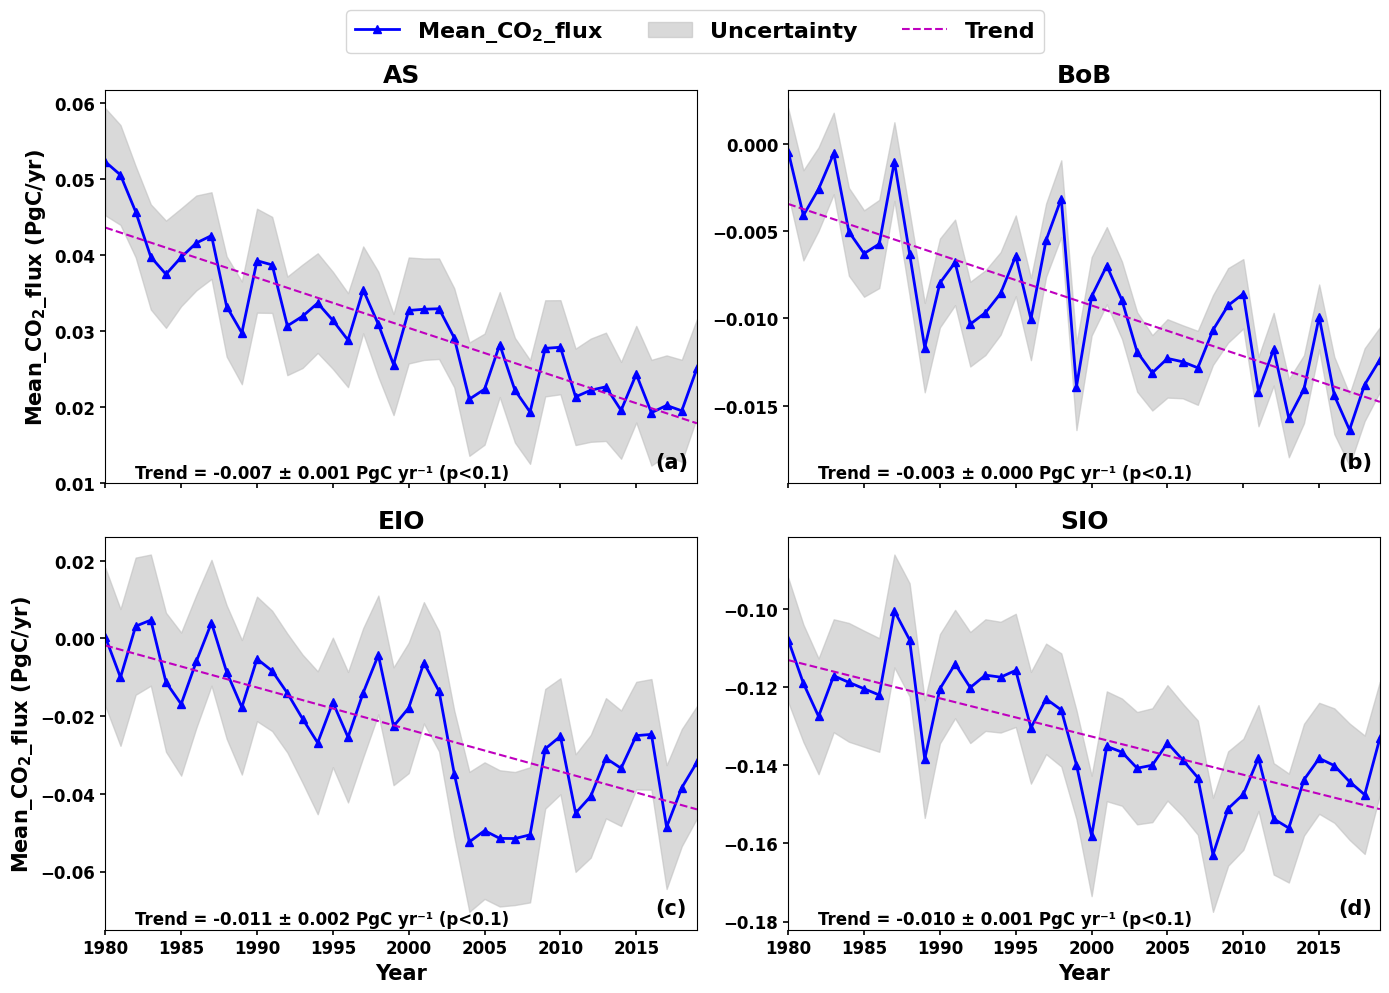

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# Region information for looping intercept_meanAS, r_meanvalue_meanAS, p_meanvalue_meanAS, std_meanerr_meanAS
regions = [
    ("AS", flux_AS_mean.values, er_un_AS.values, slope_meanAS, std_meanerr_meanAS, intercept_meanAS, (None, None)),
    ("BoB", flux_BoB_mean.values, er_un_BoB.values, slope_meanBoB, std_meanerr_meanBoB, intercept_meanBoB, (None, None)),
    ("EIO", flux_EIO_mean.values, er_un_EIO.values, slope_meanEIO, std_meanerr_meanEIO, intercept_meanEIO, (None, None)),
    ("SIO", flux_SIO_mean.values, er_un_SIO.values, slope_meanSIO, std_meanerr_meanSIO, intercept_meanSIO, (None, None)),
]

for i, (title, amp, err, slope, slope_err, intercept, ylim) in enumerate(regions):
    ax = axes[i]
    ax.margins(x=0)

    # Plot amplitude + error shading
    ax.plot(years, amp, marker="^", c="b", label=r"Mean_$\mathbf{CO_{2}}$_flux",linewidth=2)
    ax.fill_between(years, amp - err, amp + err, color="silver", alpha=0.6, label="Uncertainty")

    # Trend line
    ax.plot(years, intercept + slope * years, "m--", label="Trend")

    # Titles and limits
    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlim([1979.99, 2019.01])
    if ylim[0] is not None:
        ax.set_ylim(ylim)
    if i in [0,1,2]:
    # Add trend annotation (inside each subplot)
        ax.text(
            0.05, 0.05,
            f"Trend = {slope*10:.3f} ± {slope_err*10:.3f} PgC yr⁻¹ (p<0.1)",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            va="top",
            ha="left",
            c="k"
        )
    else:
        ax.text(
            0.05, 0.05,
            f"Trend = {slope*10:.3f} ± {slope_err*10:.3f} PgC yr⁻¹ (p<0.1)",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            va="top",
            ha="left",
            c="k"
        )

    # Subplot labels (a), (b), (c), (d)
    ax.text(0.93, 0.08, f"({chr(ord('a') + i)})",
            transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")

    # Axis labels
    if i in [2, 3]:  # bottom row
        ax.set_xlabel("Year", fontsize=15, fontweight="bold")
    else:
        ax.set_xticklabels([])  # hide xtick labels for top row
        
    if i in [0, 2]:  # left column
        ax.set_ylabel(r"Mean_$\mathbf{CO_{2}}$_flux (PgC/yr)", fontsize=15, fontweight="bold")

    ax.tick_params(axis="both", labelsize=12, width=1.2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")


legend_font = FontProperties(weight="bold", size=16)
# Add legend only once, below all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3,  prop=legend_font)

plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for legend
# plt.savefig('trend_pco2_flux_interannual.png', dpi=800, bbox_inches='tight', facecolor='white')
plt.show()
